# Adult Mouse Brain Coronal Section (10X Genomics)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2025-11-15
> - Modified: 2025-11-15

---

> - [Visium HD Spatial Gene Expression Library, Mouse Brain (Fresh Frozen)](https://www.10xgenomics.com/datasets/visium-hd-cytassist-gene-expression-mouse-brain-fresh-frozen)
> - Organism: Mus musculus
> - Brain Coronal Section
> - 10X Visium Spatial Protocols (HD)
> - 2024-09-18

---

# Experimental Design

> - Visium HD Spatial Gene Expression Reagent Kits User Guide (CG000685)
> - Slide serial number: H1-7JN9RJG
> - Area: A-1
> - Instrument: Visium CytAssist
> - Probe set: Visium Mouse Transcriptome Probe Set v2.0
> - H&E image
> - Illumina NovaSeq 6000
> - Space Ranger v3.1.1

| Sample | Tissue | Organ | Strain | Gender | Age | Sample status | Disease status |
| - | - | - | - | - | - | - | - |
| Donor | Coronal Section | Brain | C57BL/6 | Male | 8 weeks | Fresh Frozen | Healthy |

---

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/dataset_10xGenomics/Ms_Brain_VisiumHD_FF"

In [3]:
dir.create(file.path(data_dir, "result"), 
           recursive = TRUE, showWarnings = FALSE)
dir.create(file.path(data_dir, "visualization"), 
           recursive = TRUE, showWarnings = FALSE)

In [4]:
strna <- file.path(data_dir, "outs") |> 
    Load10X_Spatial(bin.size = c(16, 8))

ERROR: Error in Read10X_Coordinates(filename = Sys.glob(file.path(image.dir, : Please install arrow to read parquet files


In [ ]:
strna

# 2. Quality Control

## 2). Visualizate Metrics

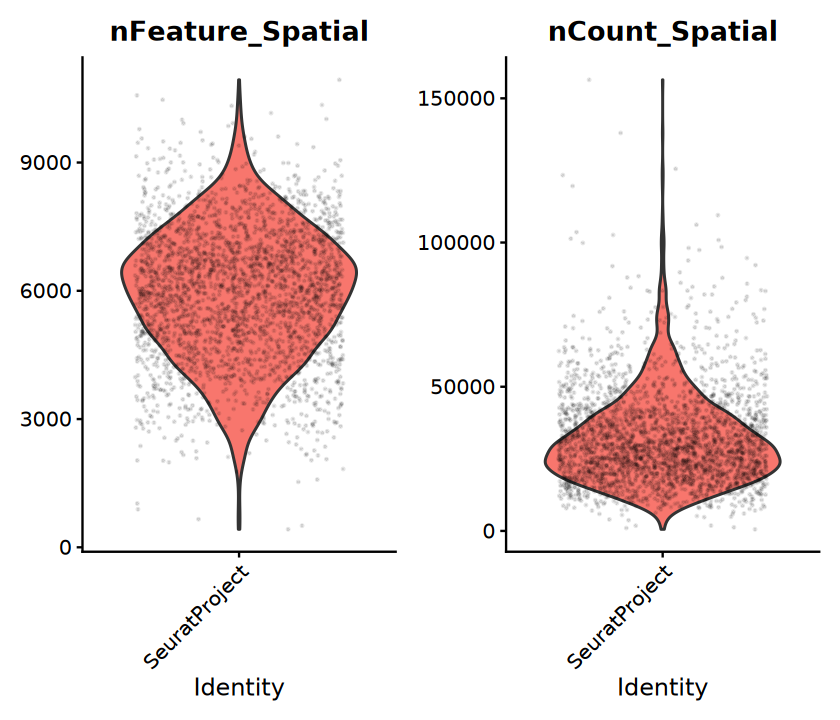

In [9]:
options(repr.plot.width = 7, repr.plot.height = 6)
VlnPlot(strna, layer = "counts", 
        features = c("nFeature_Spatial", "nCount_Spatial"), 
        pt.size = 0.1, alpha = 0.1, ncol = 2) + 
    NoLegend()

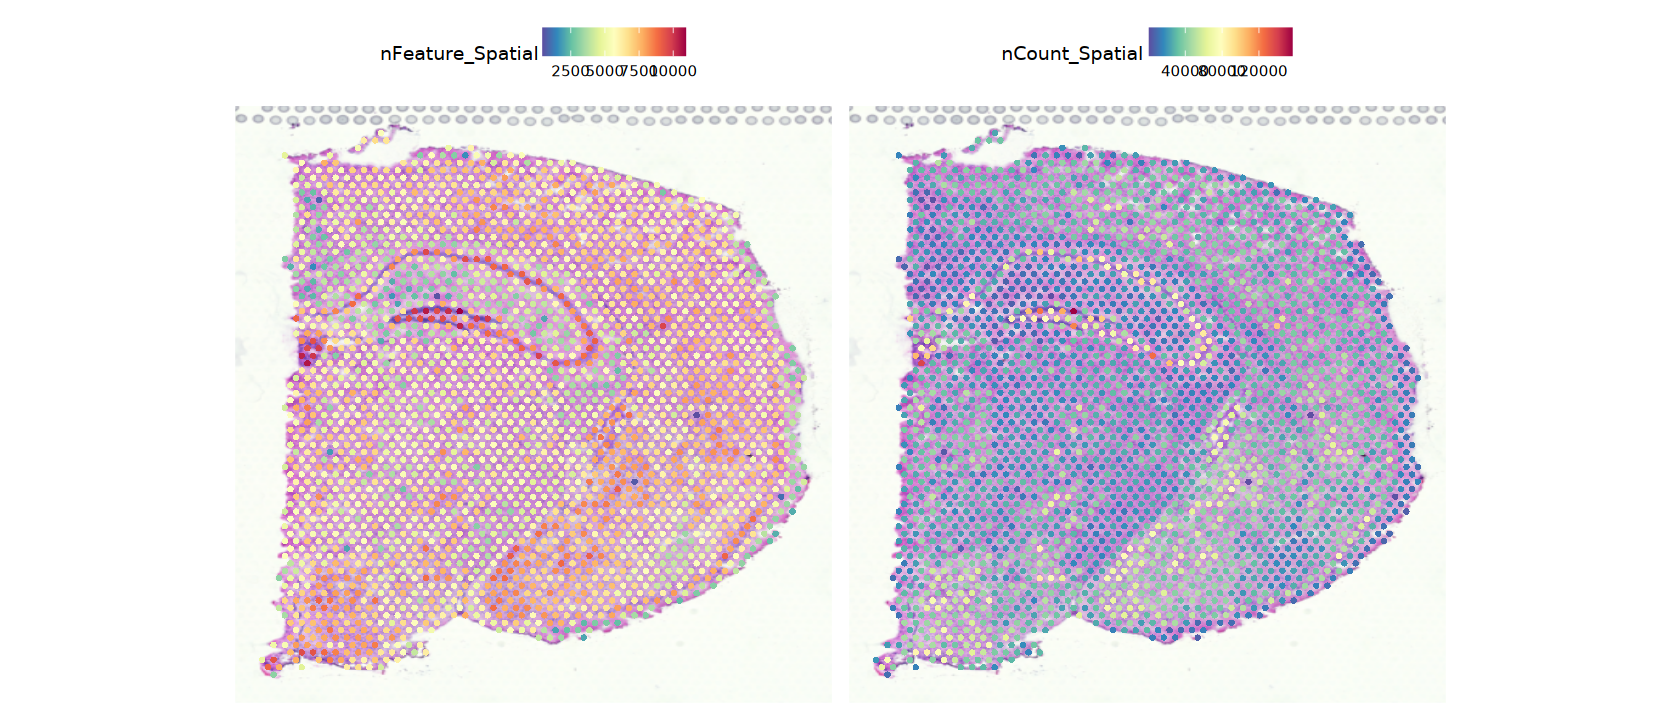

In [12]:
options(repr.plot.width = 14, repr.plot.height = 6)
SpatialFeaturePlot(strna, features = c("nFeature_Spatial", "nCount_Spatial"))

# 3. Normalization

In [15]:
strna <- NormalizeData(strna, assay = "Spatial", verbose = FALSE)
strna

An object of class Seurat 
51053 features across 2702 samples within 2 assays 
Active assay: SCT (18768 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: Spatial
 1 spatial field of view present: slice1

## b). SCTransform

In [13]:
strna <- SCTransform(
    strna, return.only.var.genes = FALSE,
    assay = "Spatial", verbose = FALSE)
strna

An object of class Seurat 
51053 features across 2702 samples within 2 assays 
Active assay: SCT (18768 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: Spatial
 1 spatial field of view present: slice1

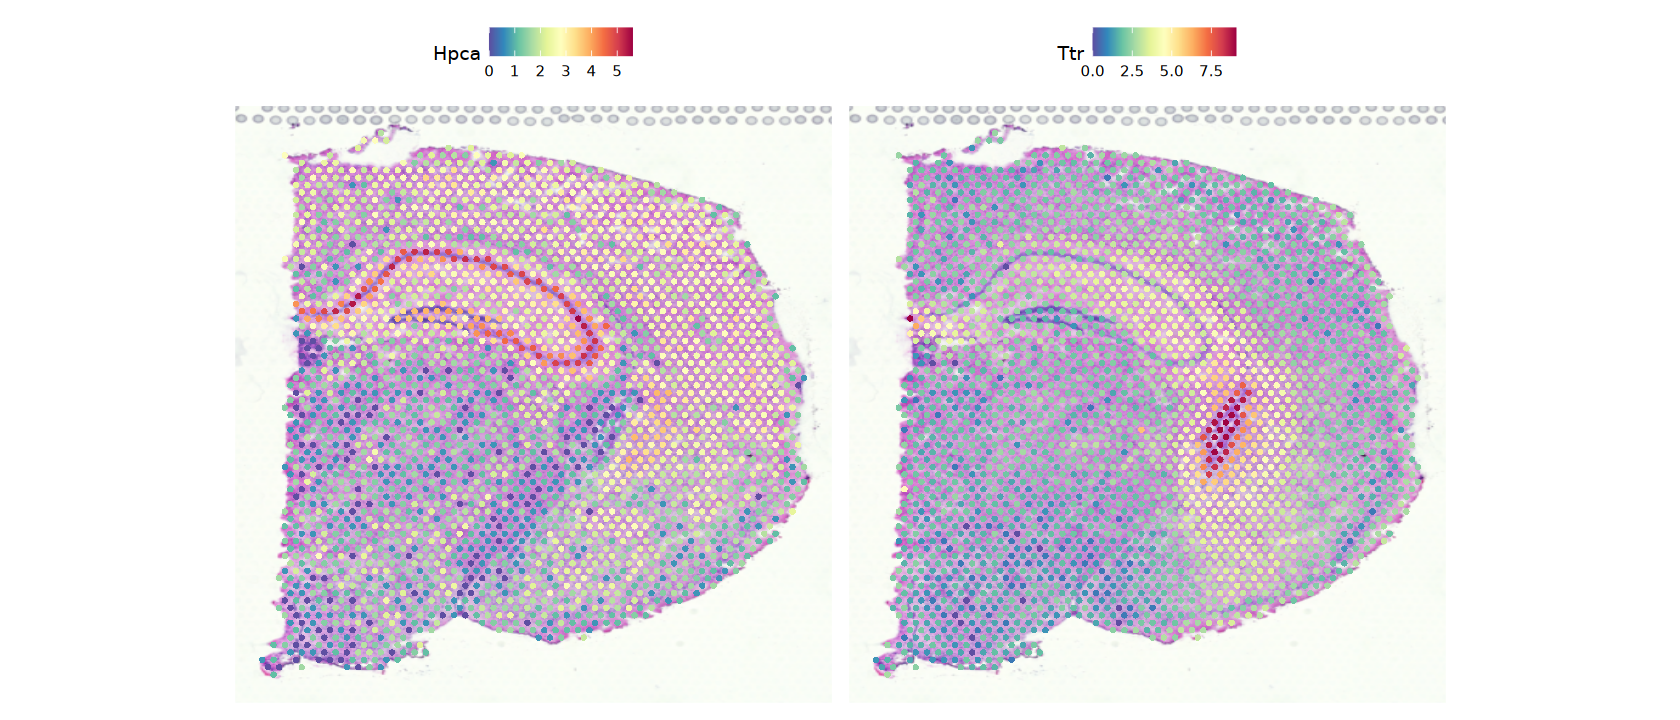

In [18]:
options(repr.plot.width = 14, repr.plot.height = 6)
SpatialFeaturePlot(strna, features = c("Hpca", "Ttr"))

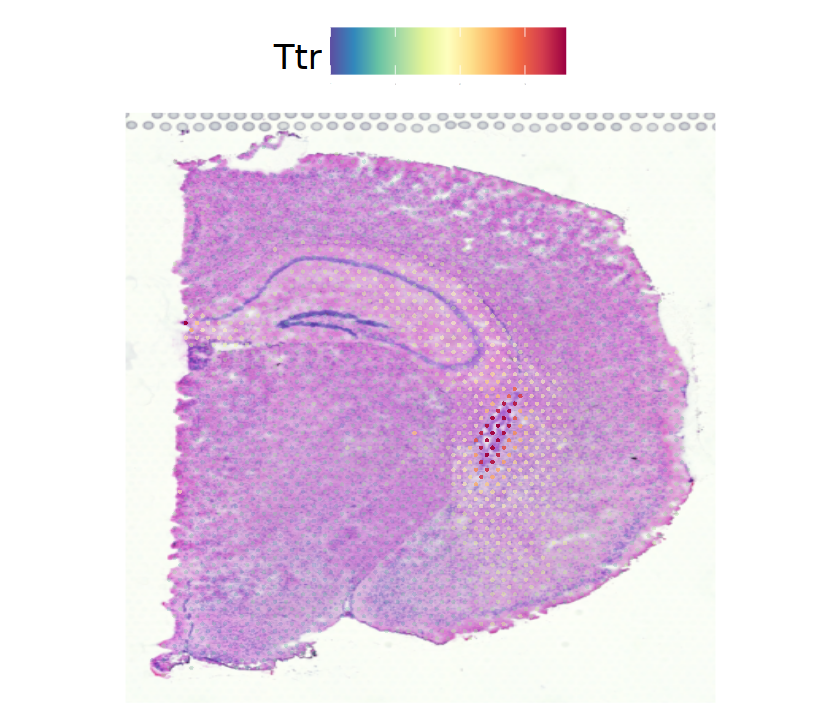

In [25]:
options(repr.plot.width = 7, repr.plot.height = 6)
SpatialFeaturePlot(strna, features = c("Ttr"), 
                   pt.size.factor = 1, alpha = c(0.1, 1)) + 
    theme(legend.text = element_text(size = 0),
          legend.title = element_text(size = 20), 
          legend.key.size = unit(1, "cm"))

# 4. Dimensionality Reduction

In [26]:
strna <- RunPCA(
    strna, assay = "SCT", npcs = 50, verbose = FALSE)
strna

An object of class Seurat 
51053 features across 2702 samples within 2 assays 
Active assay: SCT (18768 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: Spatial
 1 dimensional reduction calculated: pca
 1 spatial field of view present: slice1

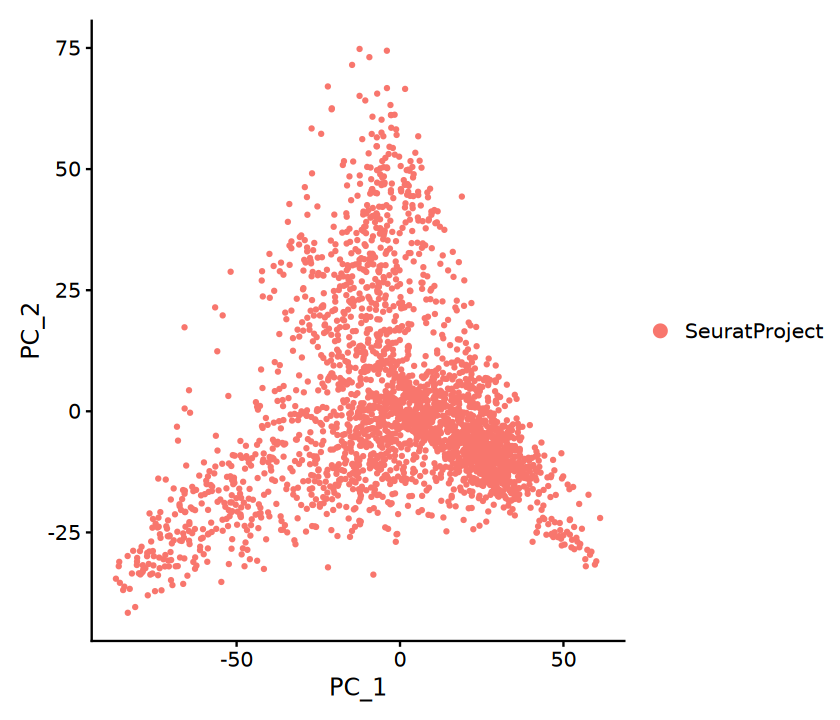

In [27]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(strna, reduction = "pca")

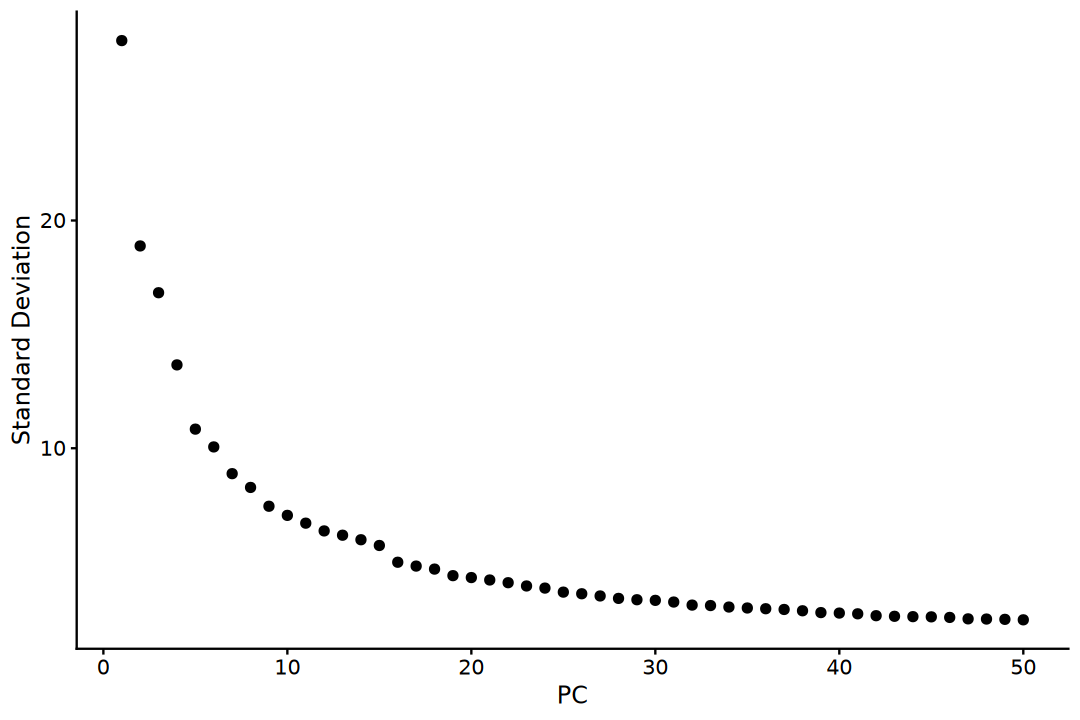

In [28]:
# Elbow plot
options(repr.plot.width = 9, repr.plot.height = 6)
ElbowPlot(strna, ndims = 50)

In [29]:
# Estimating PCA dimensionality
pca_var <- strna@reductions$pca@stdev^2
pca_con <- pca_var / sum(pca_var)
nPCs <- which(cumsum(pca_con) > 0.9 & pca_con < 0.05)[1]
print(nPCs)

[1] 22


In [30]:
nPCs <- 30

# 6. Clustering

## 1). kNN graph

Nearest-neighbor graph construction

In [31]:
strna <- FindNeighbors(
    strna, features = VariableFeatures(strna), k.param = 20,
    reduction = "pca", dims = 1:nPCs, verbose = FALSE)
strna

An object of class Seurat 
51053 features across 2702 samples within 2 assays 
Active assay: SCT (18768 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: Spatial
 1 dimensional reduction calculated: pca
 1 spatial field of view present: slice1

In [32]:
strna <- FindClusters(strna, resolution = 0.5, verbose = FALSE)

In [33]:
strna <- RunUMAP(
    strna, dims = 1:nPCs, reduction = "pca",
    n.neighbors = 30, min.dist = 0.3, verbose = FALSE)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


In [34]:
strna <- RunTSNE(
    strna, dims = 1:nPCs, reduction = "pca", 
    perplexity = 30, verbose = FALSE)

Scale for fill is already present.
Adding another scale for fill, which will replace the existing scale.


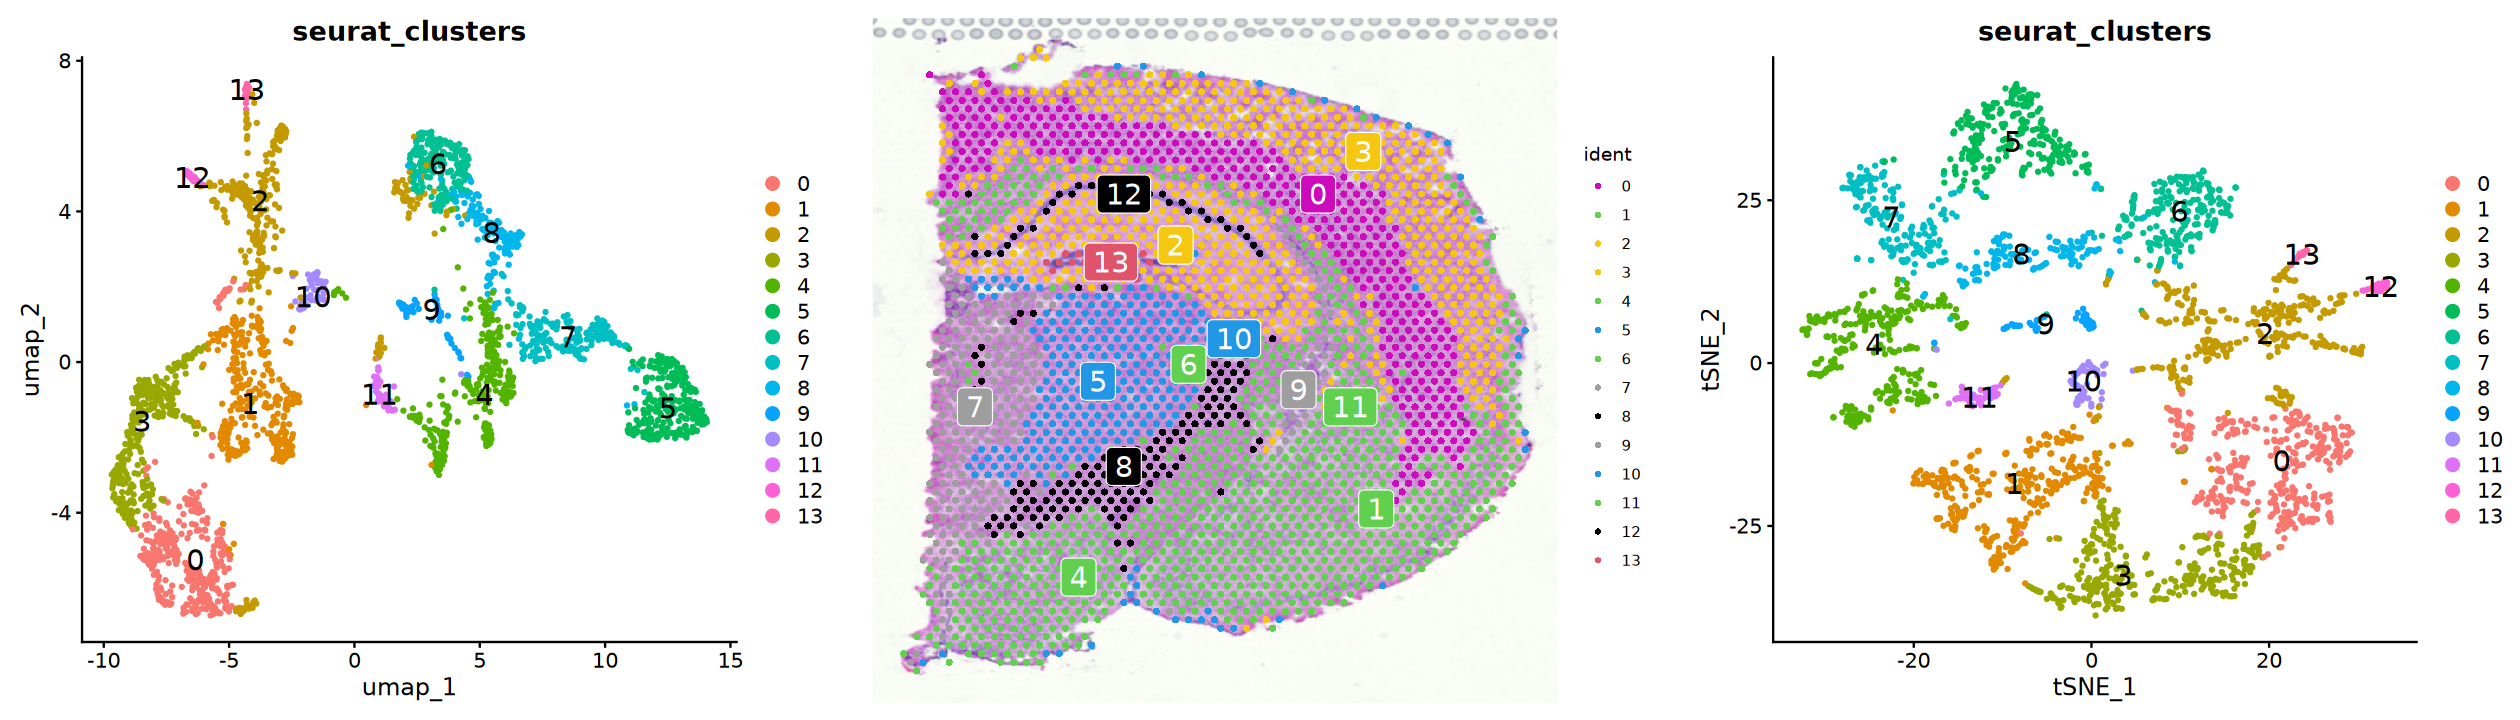

In [37]:
p1 <- DimPlot(
    strna, reduction = "umap", group.by = "seurat_clusters", 
    label = TRUE, label.size = 6, repel = FALSE)
p2 <- SpatialDimPlot(
    strna, label = TRUE, label.size = 6)
p3 <- DimPlot(
    strna, reduction = "tsne", group.by = "seurat_clusters", 
    label = TRUE, label.size = 6, repel = FALSE)

options(repr.plot.width = 21, repr.plot.height = 6)
plot_grid(p1, p2, p3, ncol = 3)

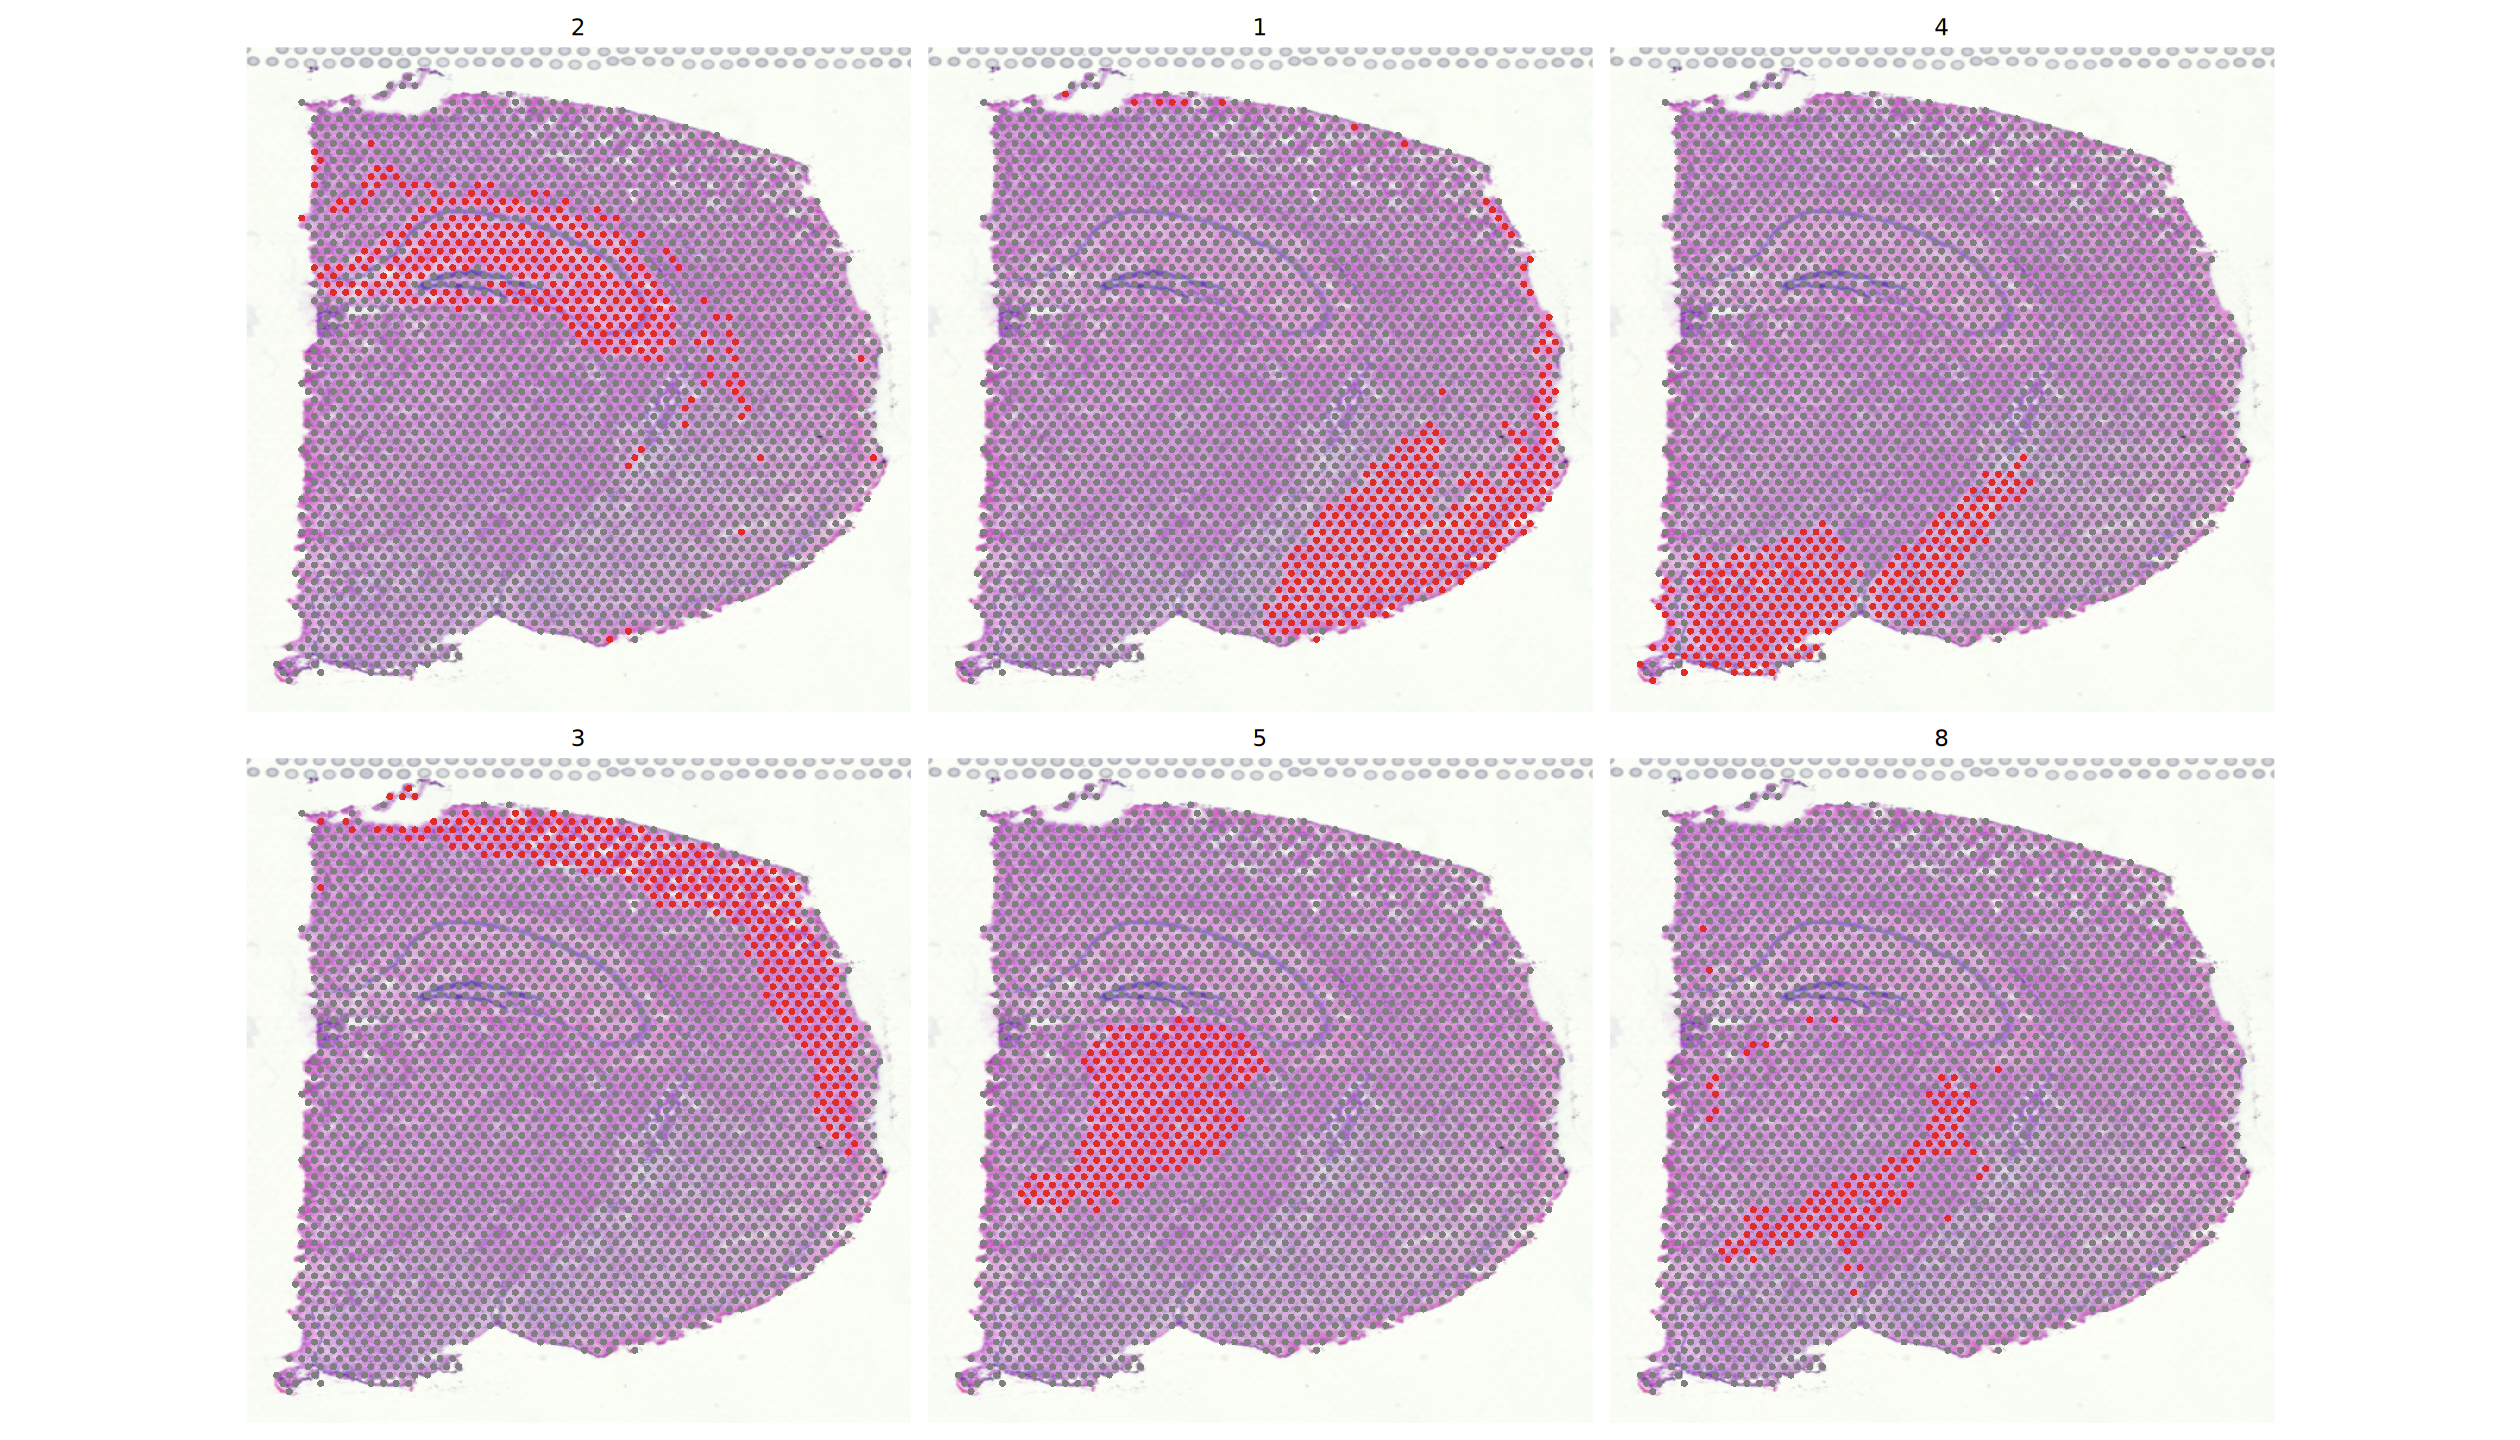

In [38]:
options(repr.plot.width = 21, repr.plot.height = 12)
SpatialDimPlot(
    strna, 
    cells.highlight = CellsByIdentities(object = strna, idents = c(2, 1, 4, 3, 5, 8)),
    facet.highlight = TRUE, ncol = 3)

In [40]:
strna

An object of class Seurat 
51053 features across 2702 samples within 2 assays 
Active assay: SCT (18768 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: Spatial
 3 dimensional reductions calculated: pca, umap, tsne
 1 spatial field of view present: slice1

# 7. Cluster Biomarkers

## Marker Identification

In [ ]:
strna <- FindSpatiallyVariableFeatures(
    strna, assay = "SCT", features = VariableFeatures(strna),
    selection.method = "moransi")
strna

In [41]:
sc.markers <- FindAllMarkers(
    strna, logfc.threshold = log2(1.2), min.pct = 0.25, 
    only.pos = FALSE, verbose = FALSE)

In [42]:
head(sc.markers)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
Hs3st2,5.224297e-161,3.002947,0.806,0.200,9.804961e-157,0,Hs3st2
Vxn,1.259494e-157,2.464170,0.989,0.648,2.363818e-153,0,Vxn
Fezf2,3.819491e-146,2.681685,0.762,0.173,7.168422e-142,0,Fezf2
Tbr1,5.173875e-137,2.164890,0.959,0.409,9.710329e-133,0,Tbr1
1110008P14Rik,1.640729e-127,1.322732,1.000,0.992,3.079321e-123,0,1110008P14Rik
Pde1a,1.802826e-127,1.786950,0.975,0.671,3.383544e-123,0,Pde1a


In [43]:
sc.markers.filt <- sc.markers |> 
    filter(p_val_adj < 0.01, 
           avg_log2FC > log2(1.2), 
           pct.1 - pct.2 > 0.2)

In [44]:
sc.markers.filt |> 
    group_by(cluster) |> 
    summarise(length(gene)) |>
    t()

cluster,0,1,2,3,4,5,6,7,8,9,10,11,12,13
length(gene),450,128,21,576,509,304,426,195,169,1437,495,286,753,616


In [45]:
top10 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC)

top3 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(3, wt = avg_log2FC)

## Visualization

Warning message in DoHeatmap(strna, slot = "scale.data", features = top3$gene, size = 8):
“The following features were omitted as they were not found in the scale.data layer for the SCT assay: Rtl3, Il20rb, Htra4, 4921539H07Rik, Stac, Ido1, Osr1, 3300002A11Rik, Slc39a4, Ccdc192, Cyp2j12, Arhgap25”


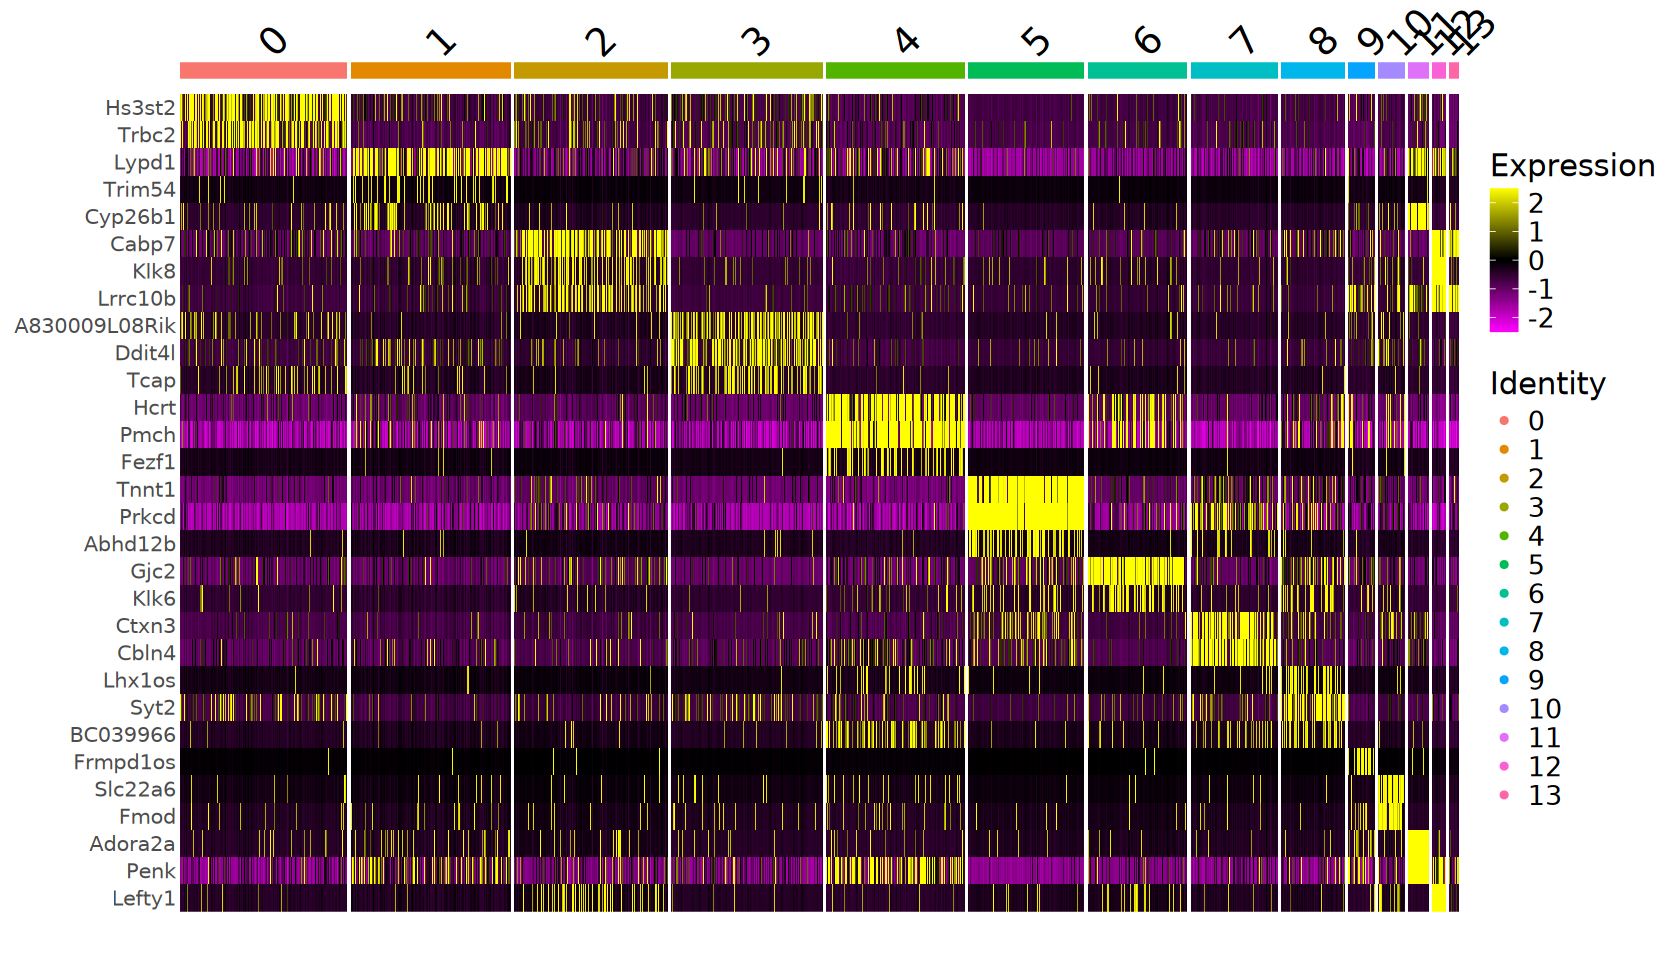

In [53]:
options(repr.plot.width = 14, repr.plot.height = 8)
DoHeatmap(strna, slot = "scale.data", 
          features = top3$gene, size = 8) +
    # scale_fill_gradientn(colors = PurpleAndYellow()) +
    theme(axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

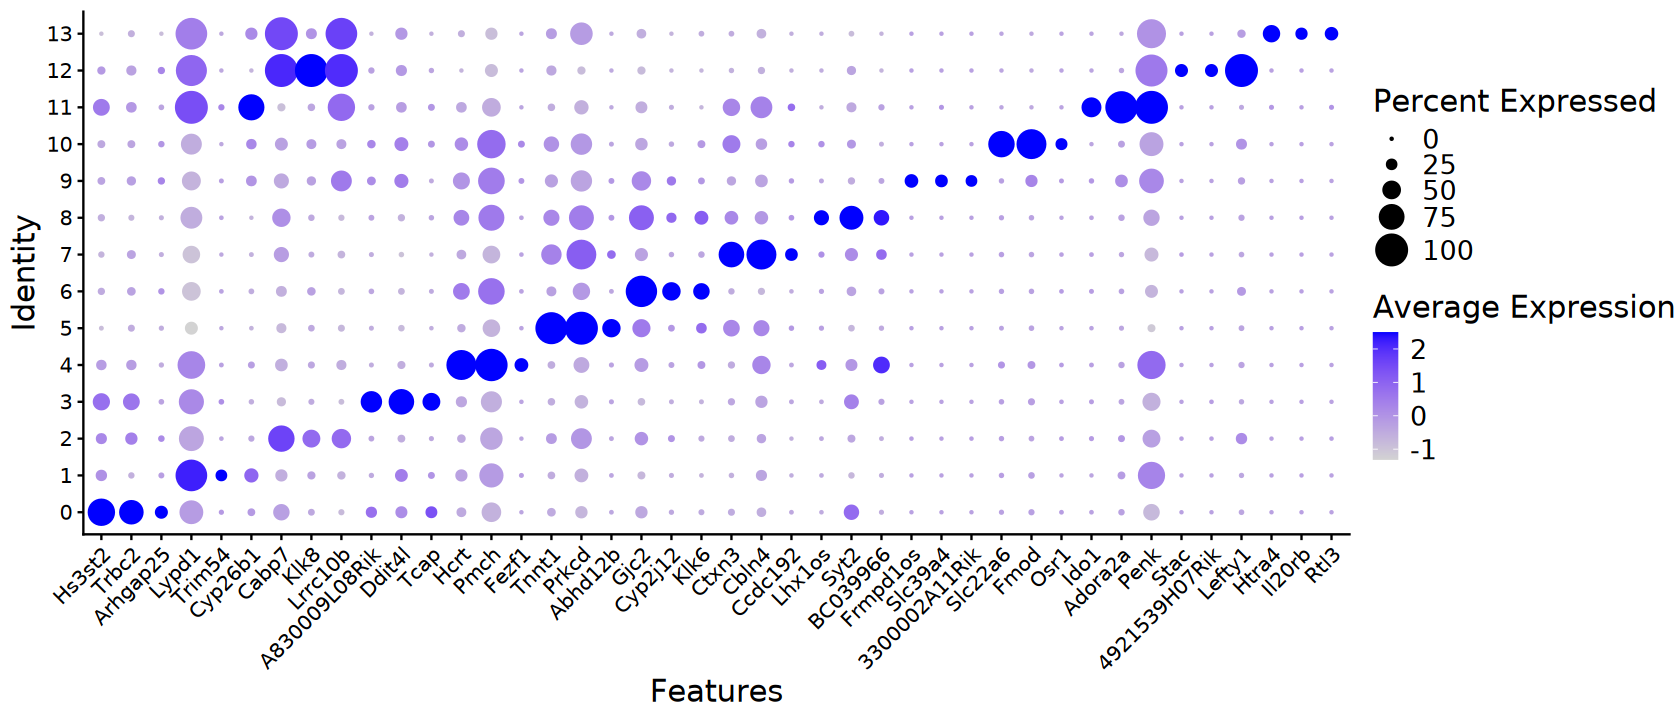

In [48]:
options(repr.plot.width = 14, repr.plot.height = 6)
DotPlot(strna, features = unique(top3$gene), dot.scale = 8) + 
    RotatedAxis() + 
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

In [ ]:
plot_dir <- file.path(
    data_dir, "visualization", "p7.1_cluster_top10_genes")

if (!dir.exists(plot_dir)) {
    dir.create(plot_dir, recursive = TRUE)
}

In [ ]:
for (index in seq(1:length(top10$gene))) {
    p1 <- VlnPlot(scrna, features = top10$gene[index])
    p2 <- FeaturePlot(
        scrna, reduction = "umap", features = top10$gene[index])
    p3 <- FeaturePlot(
        scrna, reduction = "tsne", features = top10$gene[index])
    pg <- plot_grid(p1, plot_grid(p2, p3, ncol = 2), ncol = 1)
    
    file.path(plot_dir, paste0(
        "cluster_", top10$cluster[index], "_", top10$gene[index], ".png")) |>
        ggsave(plot = pg, width = 9, height = 8)
}

# 8. Cell-type Annotation

## Manual Annotation

### Marker genes

In [49]:
gene_list <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC) |>
    summarise(genes = paste0('"', gene, '"', collapse = ", ")) |>
    mutate(out = paste0("cluster_", cluster, ": ", genes)) |> 
    pull(out)

In [50]:
gene_list |> cat(sep = "\n")

cluster_0: "Hs3st2", "Vxn", "Fezf2", "Trbc2", "Myl4", "Nxph3", "Nr4a2", "Arhgap25", "Rspo2", "Rxfp1"
cluster_1: "Slc30a3", "Lypd1", "Lmo3", "Trim54", "Hpcal1", "Mylk", "Kcng1", "Cyp26b1", "Filip1", "Ndst4"
cluster_2: "Cabp7", "Spink8", "Klk8", "Lrrc10b", "Neurod6", "Wipf3", "Hopx", "Fibcd1", "Gm2115", "Shisa6"
cluster_3: "A830009L08Rik", "Lamp5", "Ddit4l", "Tcap", "Ovol2", "Ntn5", "Gm12371", "C730002L08Rik", "Rskr", "Hkdc1"
cluster_4: "Irs4", "Gal", "Otp", "H2-Q2", "Hcrt", "Gabre", "Pmch", "Fezf1", "Ppp1r17", "Calcr"
cluster_5: "Shox2", "Tnnt1", "Rab37", "Plekhg1", "Prkcd", "Abhd12b", "Atp2a1", "Tafa4", "Vipr2", "Plekhd1"
cluster_6: "Gjc2", "Fa2h", "Ugt8a", "Opalin", "Mog", "Hapln2", "Cyp2j12", "Enpp6", "Nipal4", "Klk6"
cluster_7: "Ctxn3", "Cbln4", "Cbln1", "Lhx9", "Ccdc192", "Cbln2", "Fzd5", "Lypd6b", "Gbx2", "Lypd6"
cluster_8: "Lhx1os", "Syt2", "BC039966", "Slc32a1", "Kctd9", "Kcng4", "Zfhx4", "Esrrg", "Smim17", "Ret"
cluster_9: "Frmpd1os", "Fam166b", "Ins2", "Slc39a4", "Gm32468", "4